In [2]:


import pandas as pd

import seaborn as sb
import matplotlib.pyplot as plt
import numpy as np

In [3]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "valakhorasani/gym-members-exercise-dataset",
    "gym_members_exercise_tracking.csv"
)

df.head()

/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/28/tt6vttm91r1c29lt4s1fr9z40000gn/T/ipykernel_1038/4284422673.py:4: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    str    
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    str    
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week)  973 non-null    int64  
 13  E

In [5]:
df.describe()

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,1.256423,905.422405,24.976773,2.626619,3.321686,1.809866,24.912127
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,0.343033,272.641516,6.259419,0.600172,0.913047,0.739693,6.660879
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,1.040000,720.000000,21.300000,2.200000,3.000000,1.000000,20.110000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,1.260000,893.000000,26.200000,2.600000,3.000000,2.000000,24.160000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,1.460000,1076.000000,29.300000,3.100000,4.000000,2.000000,28.560000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


In [6]:
df['Calories_Burned'].mean()

np.float64(905.4224049331963)

In [7]:
print(df['Gender'].value_counts())
print()
print(df['Workout_Type'].value_counts())

Gender
Male      511
Female    462
Name: count, dtype: int64

Workout_Type
Strength    258
Cardio      255
Yoga        239
HIIT        221
Name: count, dtype: int64


In [8]:
male_strength = df[
    (df['Gender'] == 'Male') &
    (df['Workout_Type'] == 'Strength')
].copy()

female_strength = df[
    (df['Gender'] == 'Female') &
    (df['Workout_Type'] == 'Strength')
].copy()

male_cardio = df[
    (df['Gender'] == 'Male') &
    (df['Workout_Type'] == 'Cardio')
].copy()

female_cardio = df[
    (df['Gender'] == 'Female') &
    (df['Workout_Type'] == 'Cardio')
].copy()

In [9]:
print("Male Strength:", len(male_strength))
print("Female Strength:", len(female_strength))
print("Male Cardio:", len(male_cardio))
print("Female Cardio:", len(female_cardio))


Male Strength: 135
Female Strength: 123
Male Cardio: 129
Female Cardio: 126


In [10]:
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)',
    'Experience_Level'
]

X = df[features].copy()

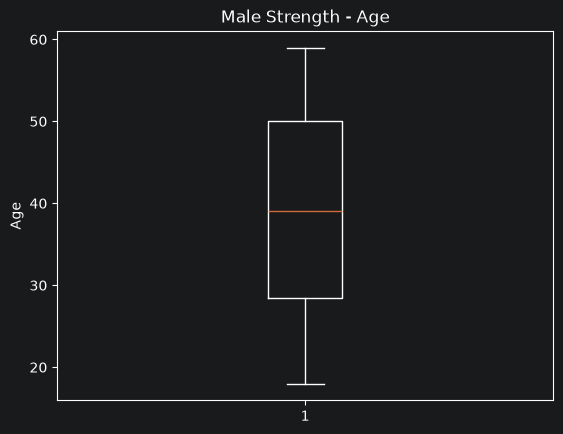

count    135.000000
mean      39.148148
std       11.935472
min       18.000000
25%       28.500000
50%       39.000000
75%       50.000000
max       59.000000
Name: Age, dtype: float64

In [11]:
#PROVERA ZA OUTLEIRE

plt.boxplot(male_strength['Age'])
plt.title('Male Strength - Age')
plt.ylabel('Age')
plt.show()

male_strength['Age'].describe()

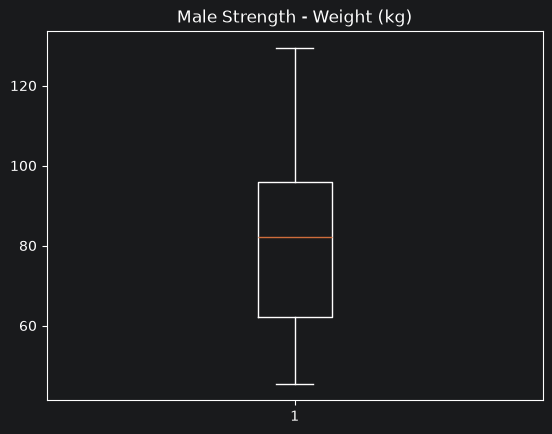

In [12]:
plt.boxplot(male_strength['Weight (kg)'])
plt.title('Male Strength - Weight (kg)')
plt.show()

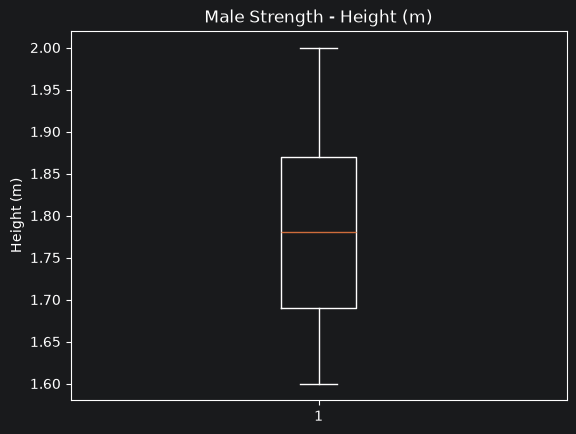

In [13]:
plt.boxplot(male_strength['Height (m)'])
plt.title('Male Strength - Height (m)')
plt.ylabel('Height (m)')
plt.show()

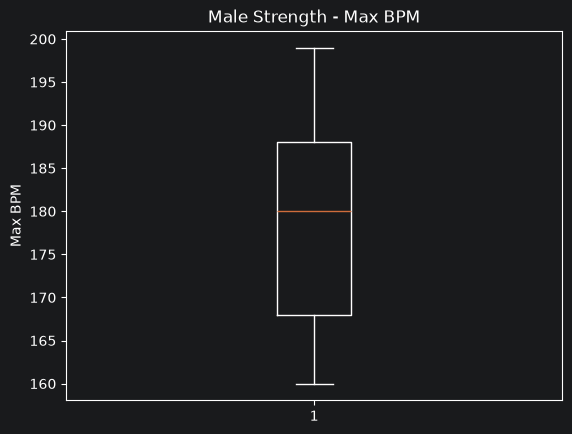

In [14]:
plt.boxplot(male_strength['Max_BPM'])
plt.title('Male Strength - Max BPM')
plt.ylabel('Max BPM')
plt.show()

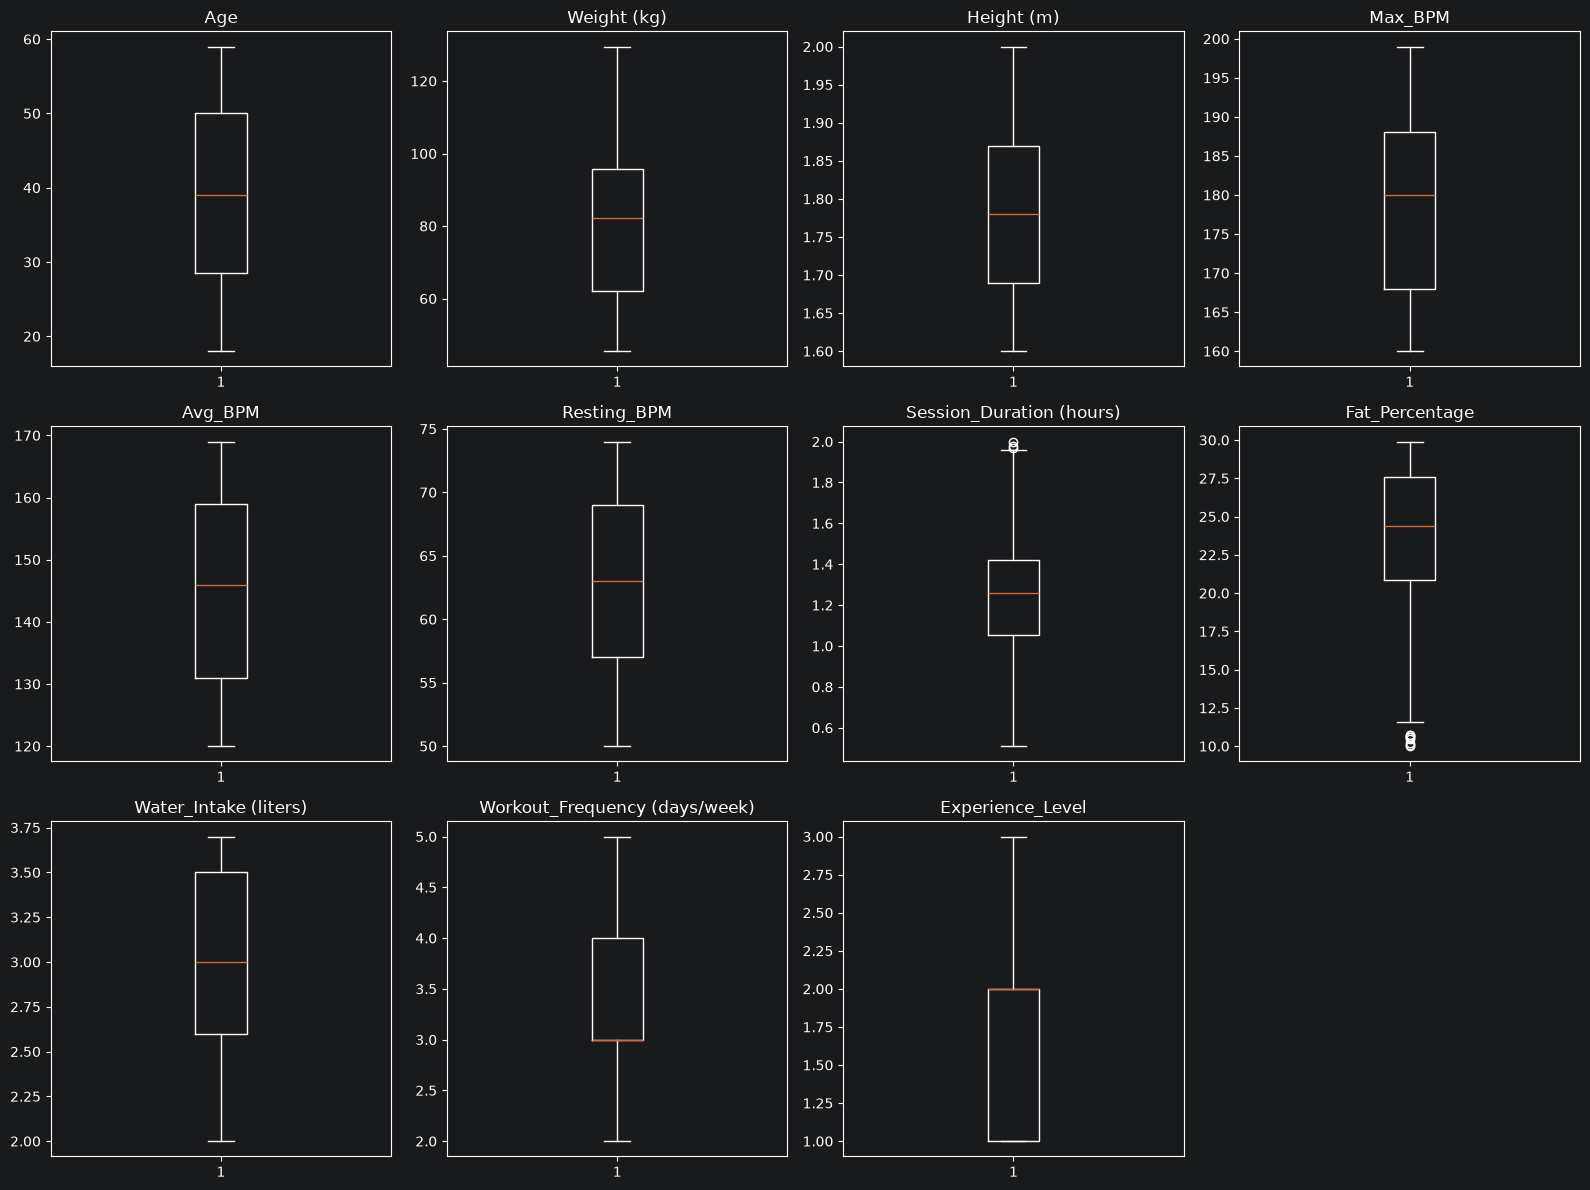

In [15]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

axes = axes.flatten()

for i, feature in enumerate(features):
    axes[i].boxplot(male_strength[feature])
    axes[i].set_title(feature)

# Sakrij višak subplot-a
for i in range(len(features), len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [16]:
#VIDIMO DA IMA OUTLIERI KOD SESSION DURATION (GORNJI) I FAT PERCENTRAGE (DONJI)

In [17]:
Q1 = male_strength['Session_Duration (hours)'].quantile(0.25)
Q3 = male_strength['Session_Duration (hours)'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_session = male_strength[
    (male_strength['Session_Duration (hours)'] < lower_bound) |
    (male_strength['Session_Duration (hours)'] > upper_bound)
]

print("Granice:", lower_bound, upper_bound)
print("Broj outliera:", len(outliers_session))
print(outliers_session['Session_Duration (hours)'].sort_values().to_string(index=False))

Granice: 0.5075000000000005 1.9674999999999996
Broj outliera: 3
1.97
1.98
2.00


In [18]:
from scipy.stats.mstats import winsorize

male_strength = male_strength.copy()

male_strength['Session_Duration (hours)'] = winsorize(
    male_strength['Session_Duration (hours)'],
    limits=[0, 0.04]
)
import matplotlib.pyplot as plt

male_strength['Fat_Percentage'] = winsorize(
    male_strength['Fat_Percentage'],
    limits=[0.06, 0]
)



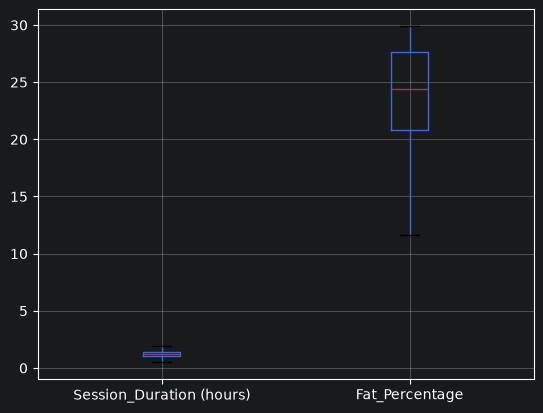

In [19]:
import matplotlib.pyplot as plt

male_strength[
    ['Session_Duration (hours)', 'Fat_Percentage']
].boxplot()

plt.show()

In [20]:
#Za 0.04 gornju grnaicu session duration nema vise outliera,a za 0.06 donju granicu fat percentage nema vise outliera

In [21]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X = male_strength[features]
X_scaled = scaler.fit_transform(X)

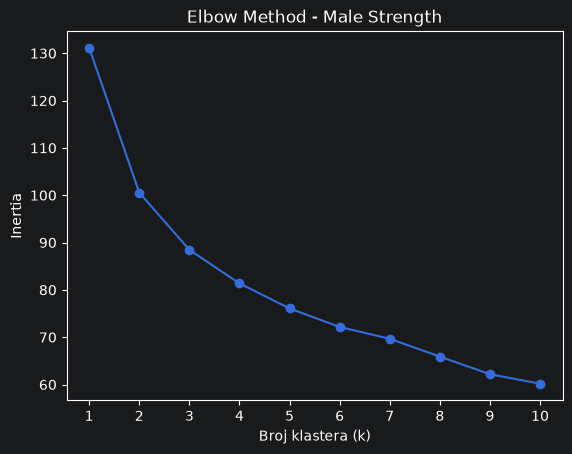

[131.16770547336185,
 100.5525843062501,
 88.4601943178561,
 81.37281957841641,
 76.07034457760761,
 72.1699731921832,
 69.66427076699776,
 65.90152754473134,
 62.17514463090795,
 60.17566859964681]

In [22]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []

K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(K, inertias, marker='o')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method - Male Strength')
plt.xticks(K)
plt.show()
inertias

k=2: 0.2751
k=3: 0.1605
k=4: 0.1445
k=5: 0.1565
k=6: 0.1465
k=7: 0.1408
k=8: 0.1385
k=9: 0.1298
k=10: 0.1300


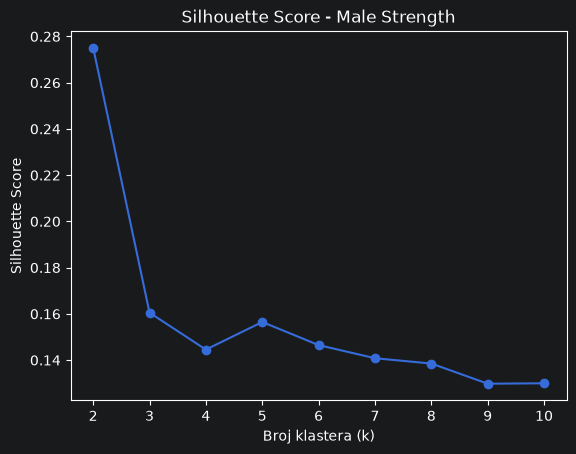

In [23]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"k={k}: {score:.4f}")

plt.plot(K, silhouette_scores, marker='o')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score - Male Strength')
plt.xticks(K)
plt.show()

In [24]:
#Iz inertia i silhouette score vidimo da su najmerodavniji k=2, za k=3 pa dalje nemamo razlog proveravati

In [25]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

male_strength['Cluster'] = kmeans.fit_predict(X_scaled)

In [26]:
male_strength['Cluster'].value_counts().sort_index()

Cluster
0    112
1     23
Name: count, dtype: int64

In [27]:
male_strength.groupby('Cluster')[features].mean().round(2)

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level
Cluster,,,,,,,,,,,
0,39.86,81.34,1.78,178.54,144.46,63.15,1.14,25.22,2.88,3.13,1.55
1,35.70,85.53,1.80,181.35,149.52,61.83,1.78,12.70,3.50,4.61,3.00


In [28]:
#Mozemo videti da se u klaster 2 nalaze muskarci malo mladji,malo vece tezine koji imaju duze treninge i cesce i imaju znatno nizi fat percentage od prvog klastera

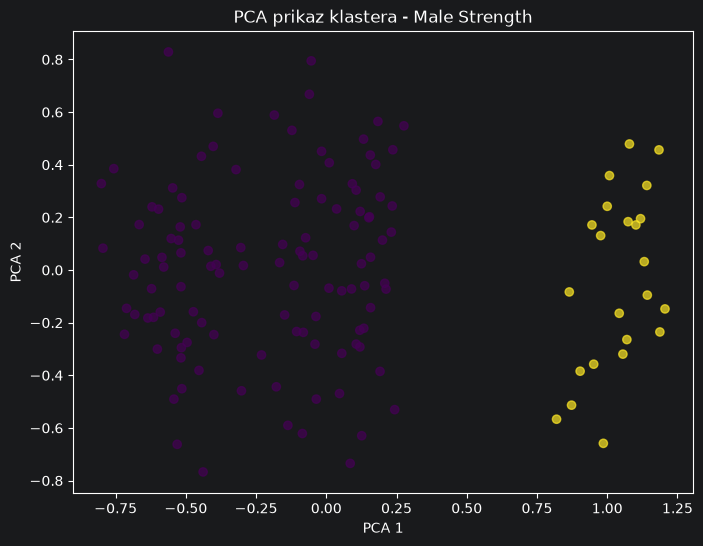

In [29]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=male_strength['Cluster'],
    alpha=0.7
)

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('PCA prikaz klastera - Male Strength')

plt.show()

In [30]:
print("Explained variance ratio:", pca.explained_variance_ratio_)
print(
    "Ukupno objašnjena varijansa:",
    pca.explained_variance_ratio_.sum()
)

Explained variance ratio: [0.31329013 0.11604104]
Ukupno objašnjena varijansa: 0.42933117008136956


In [31]:
#zajedno ove komponente objasnjavaju 43% varijanse i pca prikazuje vizuelnu strukturu klastera

In [32]:
male_strength.groupby('Cluster')['Calories_Burned'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

,count,mean,median,std
Cluster,,,,
0,112,857.36,894.0,222.30
1,23,1425.00,1404.0,199.39


In [33]:
#Utreniraniji klaster trosi oko 600 kalorija vise sto je ocekivano i imamo smislen rezultat
#Sledece idemo na female strengh gde cemo uraditi isti sablon

In [34]:
female_strength = df[
    (df['Gender'] == 'Female') &
    (df['Workout_Type'] == 'Strength')
].copy()

print(female_strength.shape)

(123, 15)


In [35]:
X_female_strength = female_strength[features]

In [36]:
corr_matrix = X_female_strength.corr()
corr_matrix

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level
Age,1.000000,-0.103662,0.072455,-0.067158,0.053819,-0.003873,0.043264,0.007710,0.109423,-0.028921,-0.040267
Weight (kg),-0.103662,1.000000,-0.052204,0.138472,0.109345,-0.087453,-0.060009,0.087556,-0.071629,0.013035,0.014922
Height (m),0.072455,-0.052204,1.000000,-0.210017,-0.029064,0.017345,-0.083288,0.108506,-0.042310,-0.075218,-0.071508
Max_BPM,-0.067158,0.138472,-0.210017,1.000000,-0.137013,0.054714,-0.048262,-0.039094,0.024466,0.051976,0.084000
Avg_BPM,0.053819,0.109345,-0.029064,-0.137013,1.000000,0.099547,-0.249862,0.271739,-0.198200,-0.099994,-0.121338
Resting_BPM,-0.003873,-0.087453,0.017345,0.054714,0.099547,1.000000,-0.128464,0.006502,0.027641,0.008062,-0.048973
Session_Duration (hours),0.043264,-0.060009,-0.083288,-0.048262,-0.249862,-0.128464,1.000000,-0.616377,0.421409,0.581267,0.745401
Fat_Percentage,0.007710,0.087556,0.108506,-0.039094,0.271739,0.006502,-0.616377,1.000000,-0.485912,-0.585509,-0.690727
Water_Intake (liters),0.109423,-0.071629,-0.042310,0.024466,-0.198200,0.027641,0.421409,-0.485912,1.000000,0.428918,0.479684
Workout_Frequency (days/week),-0.028921,0.013035,-0.075218,0.051976,-0.099994,0.008062,0.581267,-0.585509,0.428918,1.000000,0.823009


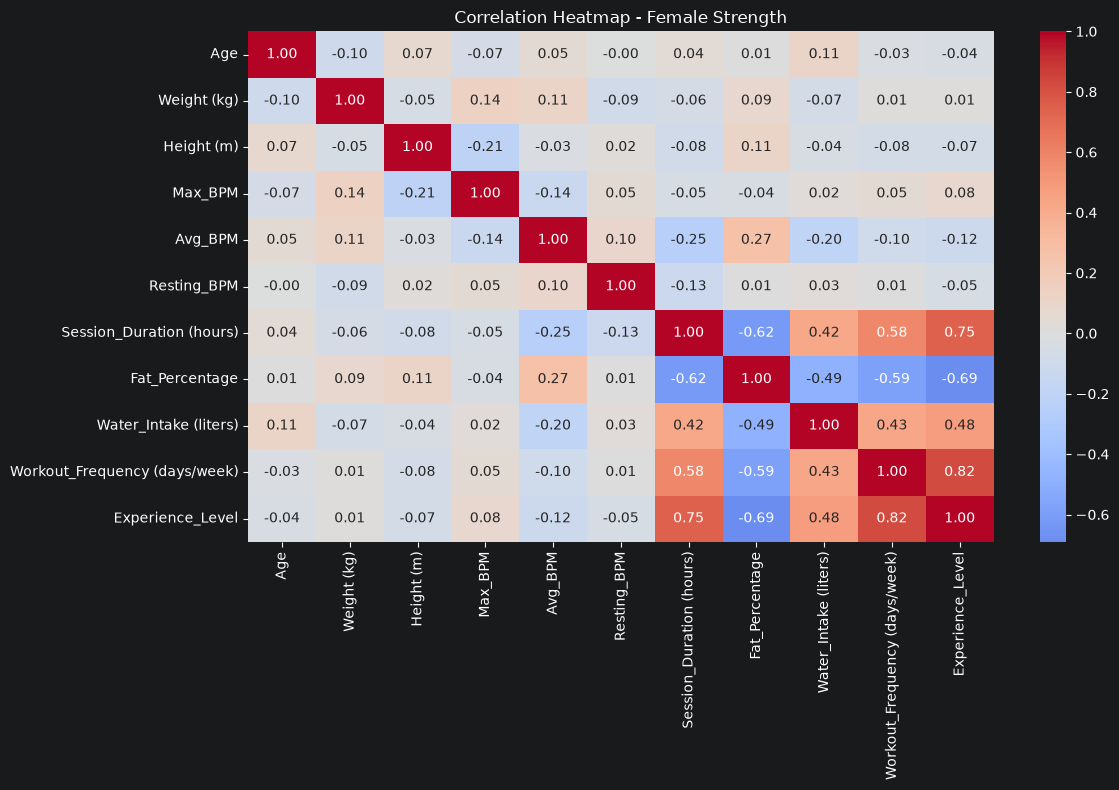

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = X_female_strength.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap - Female Strength')
plt.tight_layout()
plt.show()

In [38]:
#Nema niste preko 0.7 pa ne izabacujemo nista

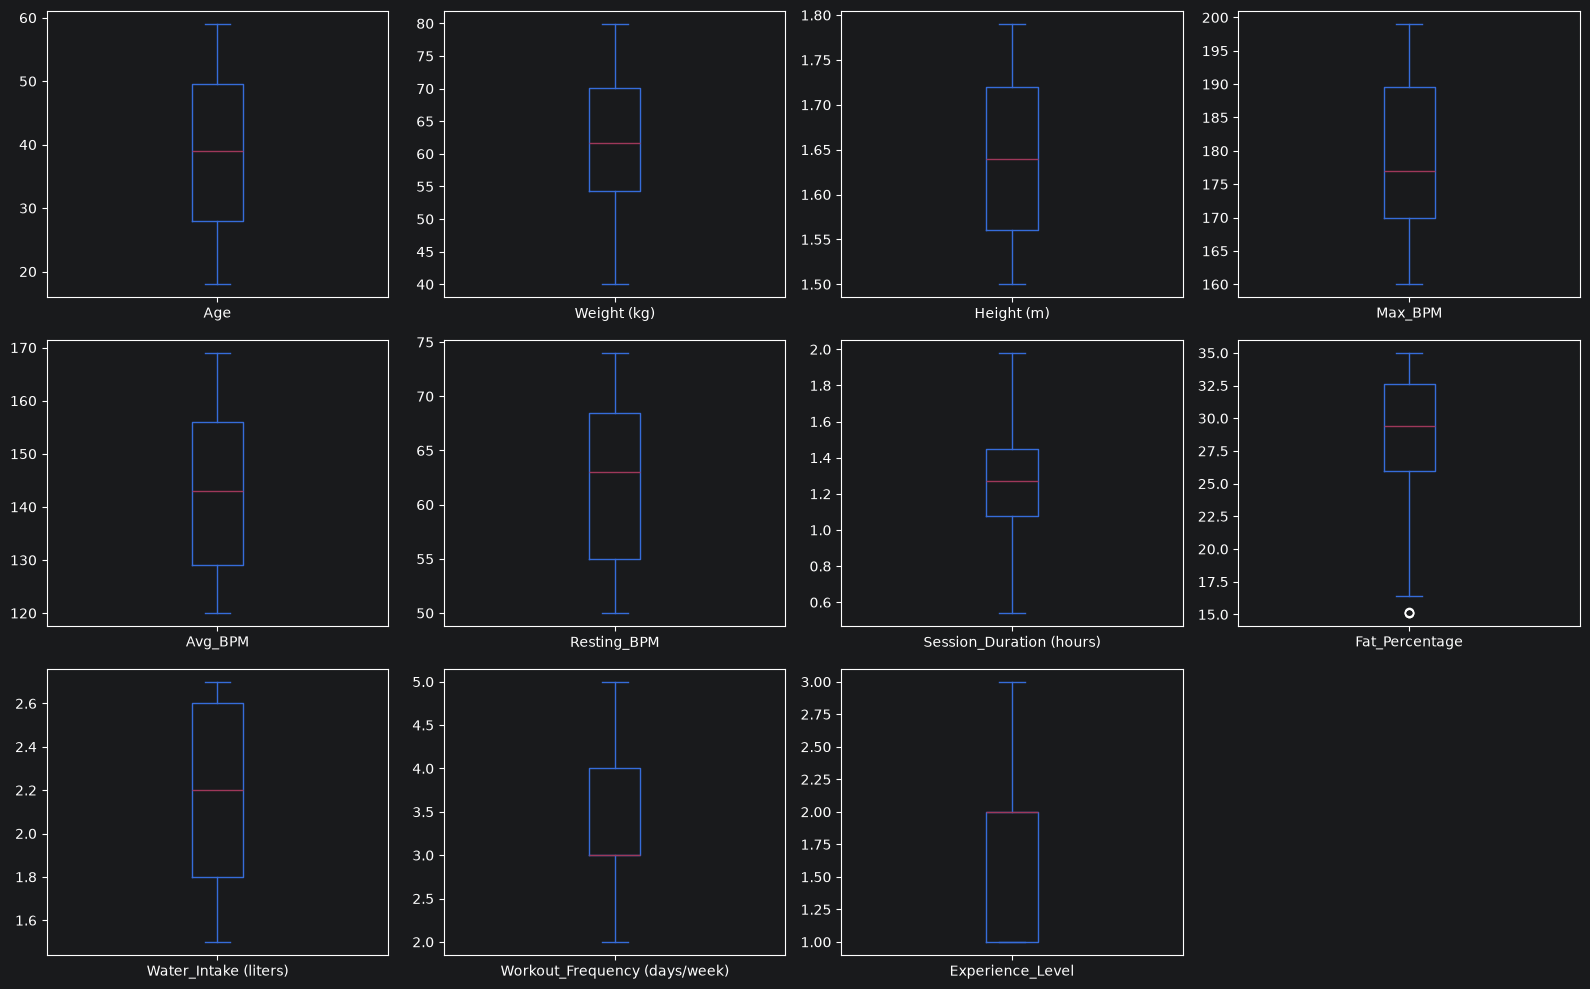

In [39]:
import matplotlib.pyplot as plt

X_female_strength.plot(
    kind='box',
    subplots=True,
    layout=(3, 4),
    figsize=(16, 10),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

In [40]:
from scipy.stats.mstats import winsorize

female_strength['Fat_Percentage'] = winsorize(
    female_strength['Fat_Percentage'],
    limits=[0.03, 0]
)
X_female_strength = female_strength[features]

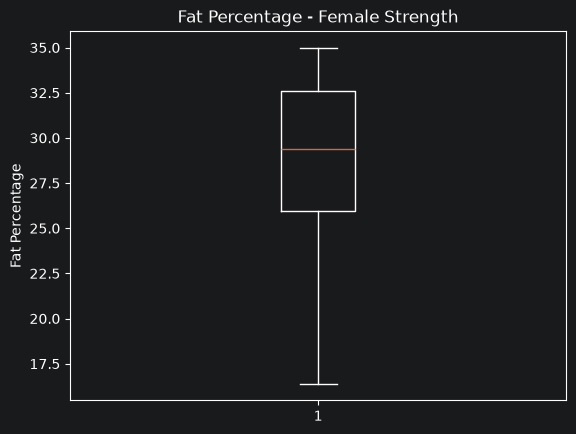

In [41]:
plt.boxplot(X_female_strength['Fat_Percentage'])
plt.ylabel('Fat Percentage')
plt.title('Fat Percentage - Female Strength')
plt.show()

In [42]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
X_female_strength = female_strength[features].copy()

In [43]:
from sklearn.preprocessing import MinMaxScaler

scaler_female_strength = MinMaxScaler()

X_scaled_female_strength = scaler_female_strength.fit_transform(
    X_female_strength
)

print(X_scaled_female_strength.shape)

(123, 11)


In [44]:
print(len(features))
print(features)

11
['Age', 'Weight (kg)', 'Height (m)', 'Max_BPM', 'Avg_BPM', 'Resting_BPM', 'Session_Duration (hours)', 'Fat_Percentage', 'Water_Intake (liters)', 'Workout_Frequency (days/week)', 'Experience_Level']


[120.54026350083458, 88.42974884842502, 78.37326543426965, 72.73409101129853, 68.57687320216203, 65.18266146247663, 61.956157309760016, 59.04336504002784, 57.23318971232601, 53.11498592714661]


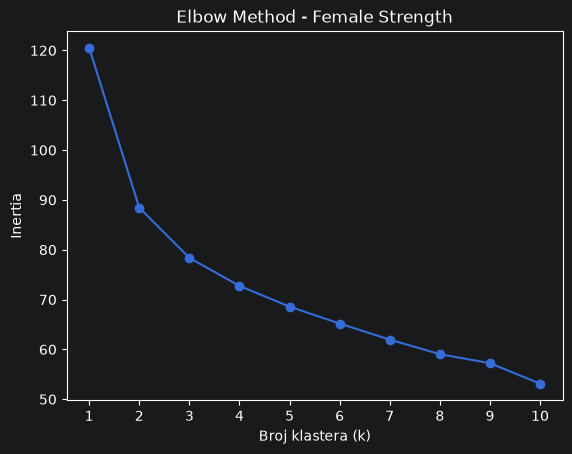

In [45]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled_female_strength)
    inertias.append(kmeans.inertia_)

print(inertias)

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method - Female Strength')
plt.xticks(range(1, 11))
plt.show()

In [46]:
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled_female_strength)

    score = silhouette_score(
        X_scaled_female_strength,
        labels
    )

    print(f"k={k}: {score:.4f}")


k=2: 0.3053
k=3: 0.1671
k=4: 0.1608
k=5: 0.1571
k=6: 0.1513
k=7: 0.1549
k=8: 0.1241
k=9: 0.1168
k=10: 0.1325


In [47]:
#opet k=2 je daleko najbolji rezultat za inertia i slhouette score

In [48]:
kmeans_female_strength = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

female_strength['Cluster'] = kmeans_female_strength.fit_predict(
    X_scaled_female_strength
)

In [49]:
female_strength['Cluster'].value_counts().sort_index()

Cluster
0    101
1     22
Name: count, dtype: int64

In [50]:
female_strength.groupby('Cluster')[features].mean().round(2)


,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level
Cluster,,,,,,,,,,,
0,38.83,61.63,1.65,178.86,145.32,62.24,1.17,30.43,2.06,3.06,1.53
1,38.27,60.10,1.62,179.86,133.55,60.68,1.78,17.81,2.70,4.55,3.00


In [51]:
#Imamo slicnu pricu kao kod male strengh, glavna razlika kod fat_percentage visina i tezina iste,zanimljvio sto je avg_bpm veci kod grupe sa manjom duzinom treninga i ucestalosti ali ne mozemo reci ista merodavno za to jos


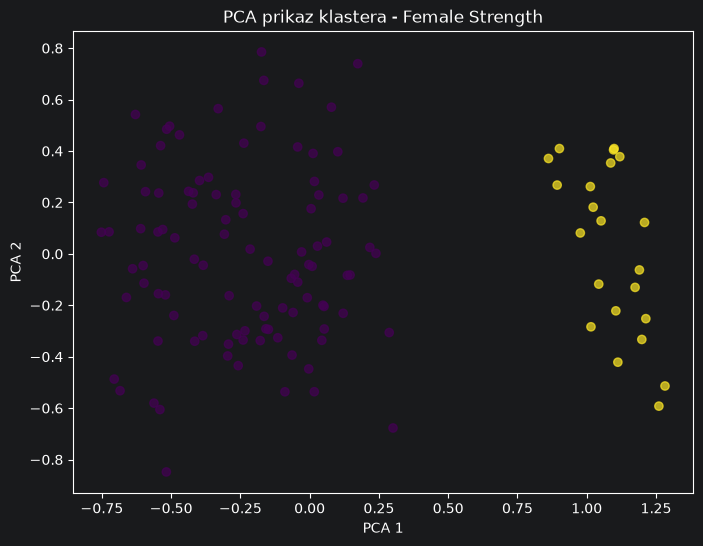

In [52]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca_female_strength = PCA(n_components=2)

X_pca_female_strength = pca_female_strength.fit_transform(
    X_scaled_female_strength
)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca_female_strength[:, 0],
    X_pca_female_strength[:, 1],
    c=female_strength['Cluster'],
    alpha=0.7
)

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('PCA prikaz klastera - Female Strength')

plt.show()

In [53]:
print(
    "Explained variance ratio:",
    pca_female_strength.explained_variance_ratio_
)

print(
    "Ukupno objašnjena varijansa:",
    pca_female_strength.explained_variance_ratio_.sum()
)

Explained variance ratio: [0.32849917 0.11565778]
Ukupno objašnjena varijansa: 0.4441569553277497


In [54]:
#U ovom slucaj je objasnjeno 39.4% varijanse

In [55]:
female_strength.groupby('Cluster')['Calories_Burned'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

,count,mean,median,std
Cluster,,,,
0,101,801.45,829.0,174.82
1,22,1146.14,1164.0,158.65


In [56]:
#Vidimo slican trend i ovde gde drugi klaster ima vecu potrosnju kalorija za oko 350 i ocekivano manje vrednosti nego u muskoj grupi

In [57]:

male_cardio = df[
    (df['Gender'] == 'Male') &
    (df['Workout_Type'] == 'Cardio')
].copy()

print(male_cardio.shape)

(129, 15)


In [58]:
#Proveravanje otuliera
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)',
    'Experience_Level'
]

for col in features:
    Q1 = male_cardio[col].quantile(0.25)
    Q3 = male_cardio[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = male_cardio[
        (male_cardio[col] < lower_bound) |
        (male_cardio[col] > upper_bound)
    ][col]

    if len(outliers) > 0:
        print(f"{col}: {len(outliers)} outliera")
        print(outliers.values)

Fat_Percentage: 10 outliera
[11.  10.7 11.6 11.  11.1 11.6 11.1 10.1 10.5 11.8]


In [59]:
from scipy.stats.mstats import winsorize

male_cardio['Fat_Percentage'] = winsorize(
    male_cardio['Fat_Percentage'],
    limits=[0.08, 0]
)

In [60]:
Q1 = male_cardio['Fat_Percentage'].quantile(0.25)
Q3 = male_cardio['Fat_Percentage'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = male_cardio[
    (male_cardio['Fat_Percentage'] < lower_bound) |
    (male_cardio['Fat_Percentage'] > upper_bound)
]

print("Broj outliera:", len(outliers))

Broj outliera: 0


/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4798: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4798: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


In [61]:
#Outlieri vise ne postoje u body fat percentage,nema vise nigde
from sklearn.preprocessing import MinMaxScaler

features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)',
    'Experience_Level'
]

X = male_cardio[features]

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(129, 11)


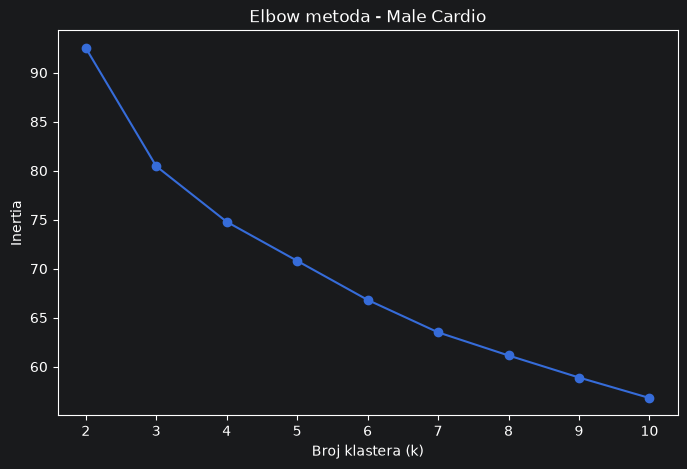

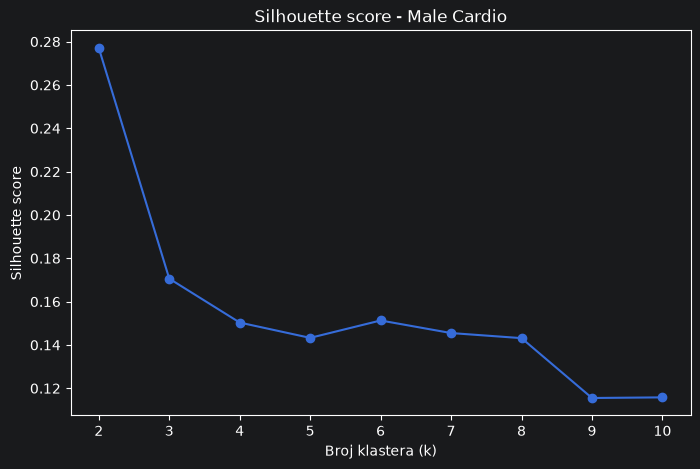

k=2: 0.2771
k=3: 0.1706
k=4: 0.1503
k=5: 0.1433
k=6: 0.1513
k=7: 0.1455
k=8: 0.1431
k=9: 0.1155
k=10: 0.1158


In [86]:
#sad radimo ko pre elbow i silhouette
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertias = []
silhouette_scores = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Elbow
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Inertia')
plt.title('Elbow metoda - Male Cardio')
plt.show()

# Silhouette
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker='o')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette score - Male Cardio')
plt.show()

for k, score in zip(k_values, silhouette_scores):
    print(f"k={k}: {score:.4f}")



In [ ]:
#opet biramo k=2,jasno je da za k=3 nemamo nikakva poboljsanja

In [90]:
kmeans_male_cardio = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

male_cardio['Cluster'] = kmeans_male_cardio.fit_predict(X_scaled)

print(male_cardio['Cluster'].value_counts().sort_index())

Cluster
0     22
1    107
Name: count, dtype: int64


In [91]:
#dobiajmo slicnu raspodelu ko kod proslih puta, sad cemo da vidimo po atributima
cluster_means_male_cardio = (
    male_cardio
    .groupby('Cluster')[features]
    .mean()
    .round(2)
)

print(cluster_means_male_cardio)

           Age  Weight (kg)  Height (m)  Max_BPM  Avg_BPM  Resting_BPM  \
Cluster                                                                  
0        39.59        85.35        1.82   175.55   141.77        64.23   
1        38.05        87.95        1.78   179.64   144.04        61.72   

         Session_Duration (hours)  Fat_Percentage  Water_Intake (liters)  \
Cluster                                                                    
0                            1.72           12.65                   3.50   
1                            1.13           25.11                   2.91   

         Workout_Frequency (days/week)  
Cluster                                 
0                                 4.45  
1                                 2.98  


In [61]:
#Opet vidimo trend gde su dosta atributa slicni ali fat percentage uvek ima znacajnu razliku kao i workout frequency i session duration gde je klaster 0 mnogo aktivniji od klastera 2 i u proseku imaju manji fat percentage

In [95]:
print(
    male_cardio
    .groupby('Cluster')['Calories_Burned']
    .mean()
    .round(2)
)

Cluster
0    1270.23
1     863.76
Name: Calories_Burned, dtype: float64


In [ ]:
#opet vidimo isti trend gde ona vise fit i aktivnija grupa sagoreva vise kalorija,oko 50% vise sto ima smisla

In [96]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Ukupno objašnjena varijansa:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.31511485 0.12320767]
Ukupno objašnjena varijansa: 0.43832251915853515


In [ ]:
#Uradjenim pca testom opet vidimo slicno stanje gde ove komponente objasnjavaju oko 43% varijanse

In [ ]:
#Jos female cardio i zavrsili smo sve 4 glavne grupe

In [97]:
female_cardio = df[
    (df['Gender'] == 'Female') &
    (df['Workout_Type'] == 'Cardio')
].copy()

print(female_cardio.shape)

(126, 15)


In [98]:
for feature in features:
    Q1 = female_cardio[feature].quantile(0.25)
    Q3 = female_cardio[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = female_cardio[
        (female_cardio[feature] < lower_bound) |
        (female_cardio[feature] > upper_bound)
    ][feature]

    if len(outliers) > 0:
        print(f"{feature}: {len(outliers)} outliera")
        print(outliers.values)
        print()

Fat_Percentage: 4 outliera
[15.5 15.9 16.2 16.1]



In [99]:
from scipy.stats.mstats import winsorize

female_cardio['Fat_Percentage'] = winsorize(
    female_cardio['Fat_Percentage'],
    limits=[0.04, 0]
)

In [101]:
Q1 = female_cardio['Fat_Percentage'].quantile(0.25)
Q3 = female_cardio['Fat_Percentage'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = female_cardio[
    (female_cardio['Fat_Percentage'] < lower_bound) |
    (female_cardio['Fat_Percentage'] > upper_bound)
]['Fat_Percentage']

print("Broj outliera:", len(outliers))
print(outliers.values)

Broj outliera: 0
[]


/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4798: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4798: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


In [102]:
#Otklonili smo outliere sad mozemo dalje na skaliranje
from sklearn.preprocessing import MinMaxScaler

X_female_cardio = female_cardio[features]

scaler_female_cardio = MinMaxScaler()
X_female_cardio_scaled = scaler_female_cardio.fit_transform(X_female_cardio)

print(X_female_cardio_scaled.shape)

(126, 10)


In [103]:
print(len(features))
print(features)

10
['Age', 'Weight (kg)', 'Height (m)', 'Max_BPM', 'Avg_BPM', 'Resting_BPM', 'Session_Duration (hours)', 'Fat_Percentage', 'Water_Intake (liters)', 'Workout_Frequency (days/week)']


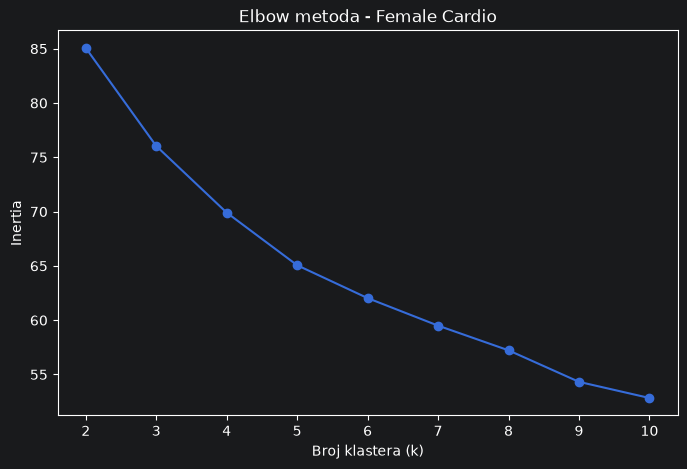

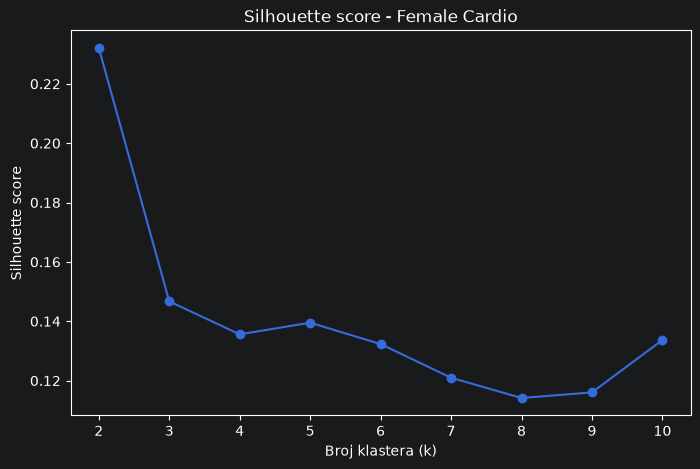

k=2: 0.2321
k=3: 0.1467
k=4: 0.1356
k=5: 0.1395
k=6: 0.1323
k=7: 0.1210
k=8: 0.1141
k=9: 0.1160
k=10: 0.1337


In [104]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertias = []
silhouette_scores = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_female_cardio_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_female_cardio_scaled, labels)
    )

# Elbow
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Inertia')
plt.title('Elbow metoda - Female Cardio')
plt.show()

# Silhouette
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker='o')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette score - Female Cardio')
plt.show()

for k, score in zip(k_values, silhouette_scores):
    print(f"k={k}: {score:.4f}")

In [ ]:
#ocekivano, k=2 je jasno opet najbolji pa biramo njega

In [105]:
kmeans_female_cardio = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

female_cardio['Cluster'] = kmeans_female_cardio.fit_predict(
    X_female_cardio_scaled
)

print(female_cardio['Cluster'].value_counts().sort_index())

Cluster
0     26
1    100
Name: count, dtype: int64


In [106]:
cluster_means_female_cardio = (
    female_cardio
    .groupby('Cluster')[features]
    .mean()
    .round(2)
)

print(cluster_means_female_cardio)

           Age  Weight (kg)  Height (m)  Max_BPM  Avg_BPM  Resting_BPM  \
Cluster                                                                  
0        37.23        61.62        1.64   183.27   142.12        61.88   
1        36.96        61.94        1.65   180.20   144.66        61.81   

         Session_Duration (hours)  Fat_Percentage  Water_Intake (liters)  \
Cluster                                                                    
0                            1.69           19.22                   2.68   
1                            1.08           30.24                   2.09   

         Workout_Frequency (days/week)  
Cluster                                 
0                                 4.50  
1                                 2.91  


In [ ]:
#isti trend ko u prosla 3 KMeans-a fat percentage mnogo nizi samo u zenskim granicama i ucestalost i duzina treninga visa kod prvog klastera

In [107]:
print(
    female_cardio
    .groupby('Cluster')['Calories_Burned']
    .mean()
    .round(2)
)

Cluster
0    1140.96
1     755.19
Name: Calories_Burned, dtype: float64


In [ ]:
#Analogno i calories burned

In [108]:
from sklearn.decomposition import PCA

pca_female_cardio = PCA(n_components=2)
X_pca_female_cardio = pca_female_cardio.fit_transform(
    X_female_cardio_scaled
)

print(
    "Explained variance ratio:",
    pca_female_cardio.explained_variance_ratio_
)

print(
    "Ukupno objašnjena varijansa:",
    pca_female_cardio.explained_variance_ratio_.sum()
)

Explained variance ratio: [0.26920995 0.1398793 ]
Ukupno objašnjena varijansa: 0.40908924340142716


In [ ]:
#Ovde nam je objasnjeno oko 41% varijanse

In [ ]:
#Sad mozemo konacno poredjenje

In [109]:
male_strength
female_strength
male_cardio
female_cardio

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,Cluster
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71,1
7,40,Female,69.7,1.51,189,141,64,1.27,895.0,Cardio,30.6,1.9,3,2,30.57,1
17,41,Female,43.8,1.77,182,165,58,1.19,884.0,Cardio,31.9,1.6,3,1,13.98,1
33,24,Female,58.9,1.51,187,157,68,1.04,816.0,Cardio,31.7,2.5,2,1,25.83,1
36,56,Female,59.3,1.56,182,155,57,1.26,879.0,Cardio,33.4,2.6,4,2,24.37,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,34,Female,66.5,1.69,191,157,52,0.81,636.0,Cardio,28.1,2.3,3,1,23.28,1
960,19,Female,69.2,1.60,186,155,74,1.17,907.0,Cardio,32.4,1.6,3,1,27.03,1
963,57,Female,43.8,1.75,180,160,73,1.39,1001.0,Cardio,25.1,1.7,2,1,14.30,1
964,56,Female,64.2,1.69,190,137,61,1.99,1227.0,Cardio,19.6,2.7,5,3,22.48,0


In [110]:
print("Male Strength:", male_strength.shape)
print("Female Strength:", female_strength.shape)
print("Male Cardio:", male_cardio.shape)
print("Female Cardio:", female_cardio.shape)

Male Strength: (135, 16)
Female Strength: (123, 16)
Male Cardio: (129, 16)
Female Cardio: (126, 16)


In [111]:
datasets = {
    'Male Strength': male_strength,
    'Female Strength': female_strength,
    'Male Cardio': male_cardio,
    'Female Cardio': female_cardio
}

for name, data in datasets.items():
    print(f"\n{name}")
    print("Broj ispitanika:", len(data))
    print("Klasteri:")
    print(data['Cluster'].value_counts().sort_index())

    print("\nCalories Burned:")
    print(
        data.groupby('Cluster')['Calories_Burned']
        .mean()
        .round(2)
    )


Male Strength
Broj ispitanika: 135
Klasteri:
Cluster
0    112
1     23
Name: count, dtype: int64

Calories Burned:
Cluster
0     857.36
1    1425.00
Name: Calories_Burned, dtype: float64

Female Strength
Broj ispitanika: 123
Klasteri:
Cluster
0    101
1     22
Name: count, dtype: int64

Calories Burned:
Cluster
0     801.45
1    1146.14
Name: Calories_Burned, dtype: float64

Male Cardio
Broj ispitanika: 129
Klasteri:
Cluster
0     22
1    107
Name: count, dtype: int64

Calories Burned:
Cluster
0    1270.23
1     863.76
Name: Calories_Burned, dtype: float64

Female Cardio
Broj ispitanika: 126
Klasteri:
Cluster
0     26
1    100
Name: count, dtype: int64

Calories Burned:
Cluster
0    1140.96
1     755.19
Name: Calories_Burned, dtype: float64


In [ ]:
#U sva 4 kmeansa imamo jedan veci klaster od oko 100 ljudi i manji od 20 i nesto sa duzim sesijama cescim treninzima nizim fat percentage

In [112]:
for name, data in datasets.items():
    print(f"\n===== {name} =====")

    print(
        data.groupby('Cluster')[features + ['Calories_Burned']]
        .mean()
        .round(2)
    )


===== Male Strength =====
           Age  Weight (kg)  Height (m)  Max_BPM  Avg_BPM  Resting_BPM  \
Cluster                                                                  
0        39.86        81.34        1.78   178.54   144.46        63.15   
1        35.70        85.53        1.80   181.35   149.52        61.83   

         Session_Duration (hours)  Fat_Percentage  Water_Intake (liters)  \
Cluster                                                                    
0                            1.14           25.22                   2.88   
1                            1.78           12.70                   3.50   

         Workout_Frequency (days/week)  Calories_Burned  
Cluster                                                  
0                                 3.13           857.36  
1                                 4.61          1425.00  

===== Female Strength =====
           Age  Weight (kg)  Height (m)  Max_BPM  Avg_BPM  Resting_BPM  \
Cluster                             

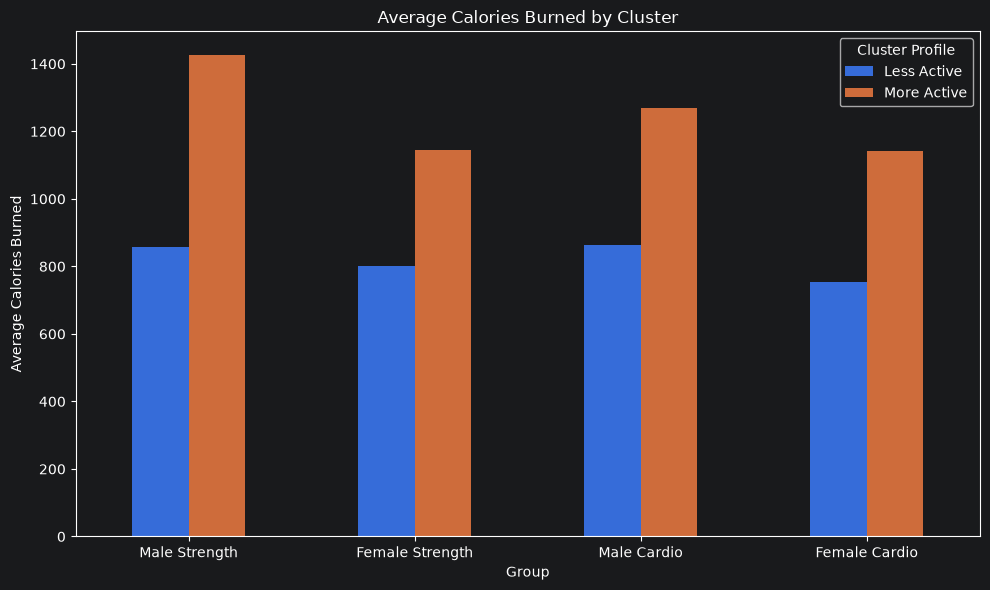

In [113]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    'Group': [
        'Male Strength',
        'Female Strength',
        'Male Cardio',
        'Female Cardio'
    ],
    'Less Active': [
        857.36,
        801.45,
        863.76,
        755.19
    ],
    'More Active': [
        1425.00,
        1146.14,
        1270.23,
        1140.96
    ]
})

comparison.set_index('Group').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Calories Burned by Cluster')
plt.xlabel('Group')
plt.ylabel('Average Calories Burned')
plt.xticks(rotation=0)
plt.legend(title='Cluster Profile')
plt.tight_layout()
plt.show()

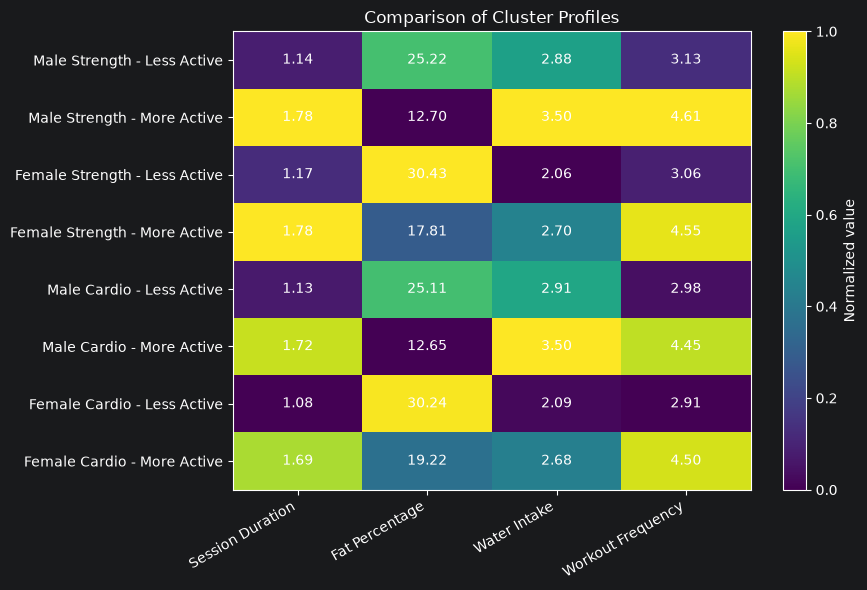

In [114]:
import pandas as pd
import matplotlib.pyplot as plt

profiles = pd.DataFrame({
    'Profile': [
        'Male Strength - Less Active',
        'Male Strength - More Active',
        'Female Strength - Less Active',
        'Female Strength - More Active',
        'Male Cardio - Less Active',
        'Male Cardio - More Active',
        'Female Cardio - Less Active',
        'Female Cardio - More Active'
    ],
    'Session Duration': [
        1.14, 1.78,
        1.17, 1.78,
        1.13, 1.72,
        1.08, 1.69
    ],
    'Fat Percentage': [
        25.22, 12.70,
        30.43, 17.81,
        25.11, 12.65,
        30.24, 19.22
    ],
    'Water Intake': [
        2.88, 3.50,
        2.06, 2.70,
        2.91, 3.50,
        2.09, 2.68
    ],
    'Workout Frequency': [
        3.13, 4.61,
        3.06, 4.55,
        2.98, 4.45,
        2.91, 4.50
    ]
})

profiles = profiles.set_index('Profile')

# Min-Max normalizacija samo za prikaz
profiles_scaled = (
    (profiles - profiles.min()) /
    (profiles.max() - profiles.min())
)

plt.figure(figsize=(9, 6))
plt.imshow(profiles_scaled, aspect='auto')

plt.colorbar(label='Normalized value')
plt.xticks(
    range(len(profiles_scaled.columns)),
    profiles_scaled.columns,
    rotation=30,
    ha='right'
)
plt.yticks(
    range(len(profiles_scaled.index)),
    profiles_scaled.index
)

# Originalne vrednosti ispisujemo u poljima
for i in range(len(profiles.index)):
    for j in range(len(profiles.columns)):
        plt.text(
            j, i,
            f'{profiles.iloc[i, j]:.2f}',
            ha='center',
            va='center'
        )

plt.title('Comparison of Cluster Profiles')
plt.tight_layout()
plt.show()

In [62]:
#ceo dataset je dole,gore ono sa 4 dataseta

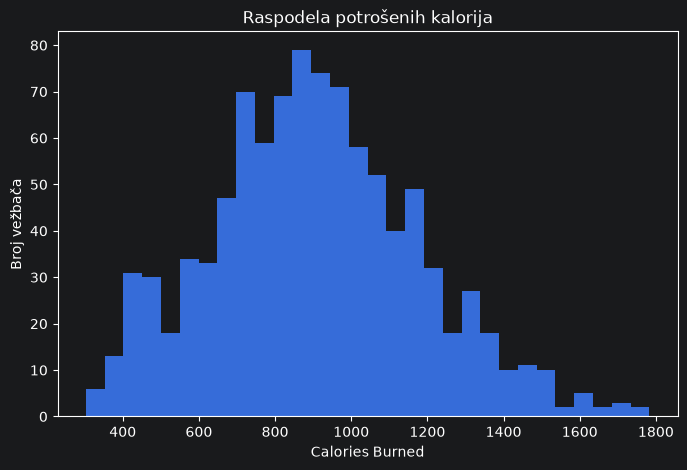

In [63]:
plt.figure(figsize=(8, 5))

plt.hist(df["Calories_Burned"], bins=30)

plt.xlabel("Calories Burned")
plt.ylabel("Broj vežbača")
plt.title("Raspodela potrošenih kalorija")

plt.show()

In [64]:
df[["Calories_Burned", "Session_Duration (hours)"]].corr()

,Calories_Burned,Session_Duration (hours)
Calories_Burned,1.00000,0.90814
Session_Duration (hours),0.90814,1.00000


In [65]:
df[["Calories_Burned", "Avg_BPM", "Weight (kg)",
    "Session_Duration (hours)"]].corr()

,Calories_Burned,Avg_BPM,Weight (kg),Session_Duration (hours)
Calories_Burned,1.000000,0.339659,0.095443,0.908140
Avg_BPM,0.339659,1.000000,0.009717,0.016014
Weight (kg),0.095443,0.009717,1.000000,-0.013666
Session_Duration (hours),0.908140,0.016014,-0.013666,1.000000


In [66]:
1.000000,0.339659,0.095443,0.908140
0.339659,1.000000,0.009717,0.016014
0.095443,0.009717,1.000000,-0.013666
0.908140,0.016014,-0.013666,1.000000


(0.90814, 0.016014, -0.013666, 1.0)

In [67]:
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)',
    'Experience_Level'
]

X = df[features].copy()

#Ostavljamo BMI van features jer je izveden iz height i weight
#Calories burned isto ne jer zelimo posle da vidimo vrednosti po klasterima

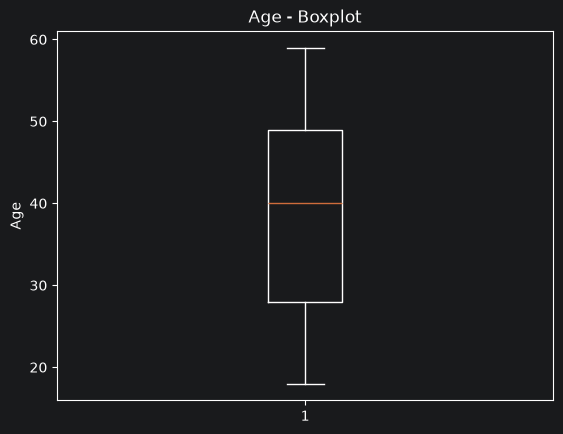

count    973.000000
mean      38.683453
std       12.180928
min       18.000000
25%       28.000000
50%       40.000000
75%       49.000000
max       59.000000
Name: Age, dtype: float64

In [68]:
from scipy.stats.mstats import winsorize

#gledanje svakog atributa za outliere

import matplotlib.pyplot as plt

plt.boxplot(df['Age'])
plt.title('Age - Boxplot')
plt.ylabel('Age')
plt.show()

df['Age'].describe()


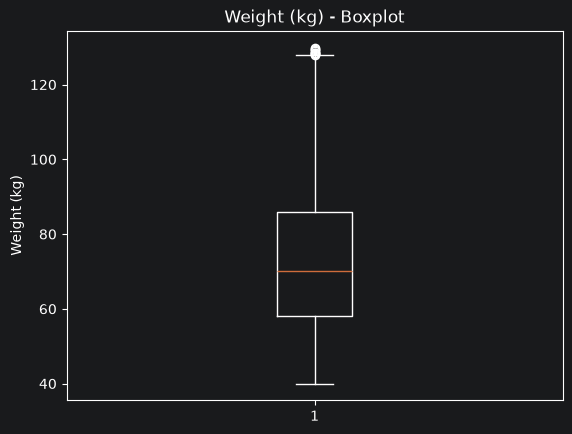

count    973.000000
mean      73.854676
std       21.207500
min       40.000000
25%       58.100000
50%       70.000000
75%       86.000000
max      129.900000
Name: Weight (kg), dtype: float64

In [69]:
plt.boxplot(df['Weight (kg)'])
plt.title('Weight (kg) - Boxplot')
plt.ylabel('Weight (kg)')
plt.show()

df['Weight (kg)'].describe()

In [70]:
Q1 = df['Weight (kg)'].quantile(0.25)
Q3 = df['Weight (kg)'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("donja granica:",lower)
print("gornja granica:",upper)

outliers = df[(df['Weight (kg)'] < lower) | (df['Weight (kg)'] > upper)]

print("Broj autlajera:",len(outliers))
print(outliers['Weight (kg)'].sort_values())








donja granica: 16.250000000000007
gornja granica: 127.85
Broj autlajera: 9
648    127.9
180    128.2
291    128.4
283    128.4
614    128.4
96     129.0
854    129.2
122    129.5
593    129.9
Name: Weight (kg), dtype: float64


In [71]:
weight_outliers = df[df['Weight (kg)'] > 127.85]

print("Broj outliera:", len(weight_outliers))
print(weight_outliers['Weight (kg)'].sort_values())

Broj outliera: 9
648    127.9
180    128.2
291    128.4
283    128.4
614    128.4
96     129.0
854    129.2
122    129.5
593    129.9
Name: Weight (kg), dtype: float64


In [72]:
from scipy.stats.mstats import winsorize
#otklanjamo gornje outliere


df['Weight (kg)'] = winsorize(
    df['Weight (kg)'],
    limits=[0, 0.01]
)

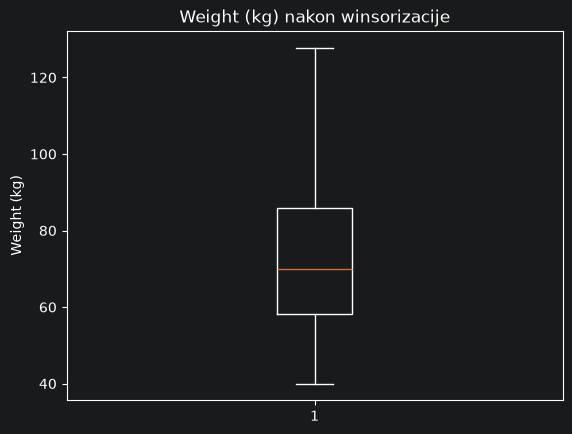

/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4798: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


count    973.000000
mean      73.845735
std       21.184429
min       40.000000
25%       58.100000
50%       70.000000
75%       86.000000
max      127.800000
Name: Weight (kg), dtype: float64

In [73]:
plt.boxplot(df['Weight (kg)'])
plt.title('Weight (kg) nakon winsorizacije')
plt.ylabel('Weight (kg)')
plt.show()

df['Weight (kg)'].describe()

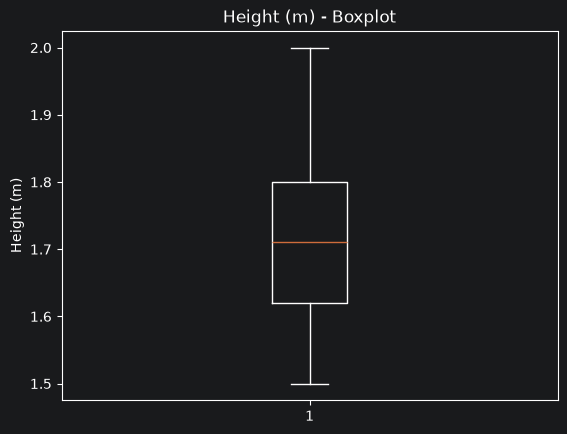

count    973.00000
mean       1.72258
std        0.12772
min        1.50000
25%        1.62000
50%        1.71000
75%        1.80000
max        2.00000
Name: Height (m), dtype: float64

In [74]:
plt.boxplot(df['Height (m)'])
plt.title('Height (m) - Boxplot')
plt.ylabel('Height (m)')
plt.show()

df['Height (m)'].describe()

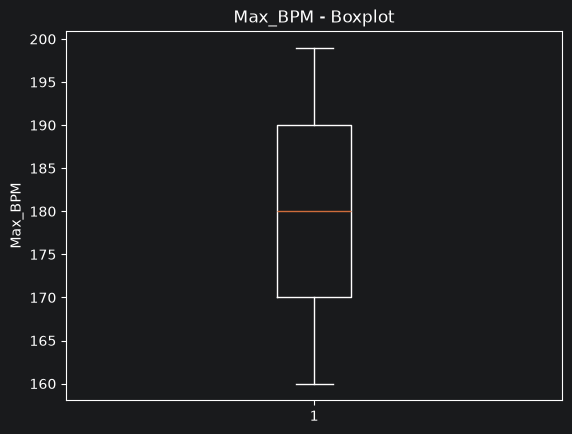

count    973.000000
mean     179.883864
std       11.525686
min      160.000000
25%      170.000000
50%      180.000000
75%      190.000000
max      199.000000
Name: Max_BPM, dtype: float64

In [75]:
plt.boxplot(df['Max_BPM'])
plt.title('Max_BPM - Boxplot')
plt.ylabel('Max_BPM')
plt.show()

df['Max_BPM'].describe()

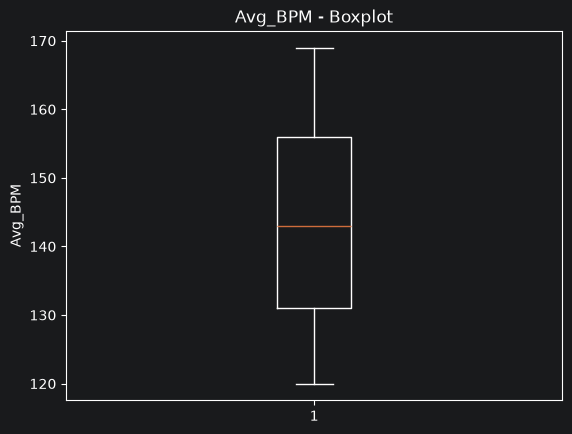

In [76]:
plt.boxplot(df['Avg_BPM'])
plt.title('Avg_BPM - Boxplot')
plt.ylabel('Avg_BPM')
plt.show()

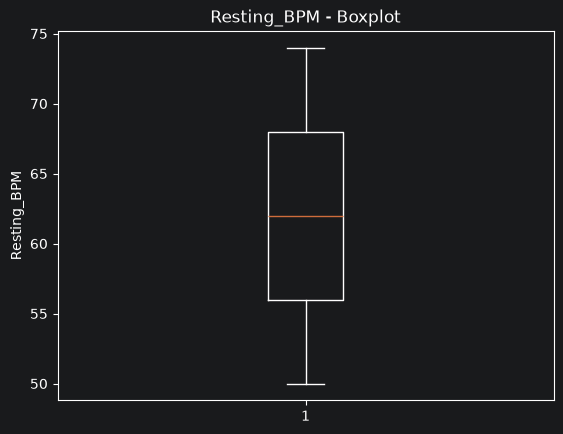

count    973.000000
mean      62.223022
std        7.327060
min       50.000000
25%       56.000000
50%       62.000000
75%       68.000000
max       74.000000
Name: Resting_BPM, dtype: float64

In [77]:
plt.boxplot(df['Resting_BPM'])
plt.title('Resting_BPM - Boxplot')
plt.ylabel('Resting_BPM')
plt.show()

df['Resting_BPM'].describe()

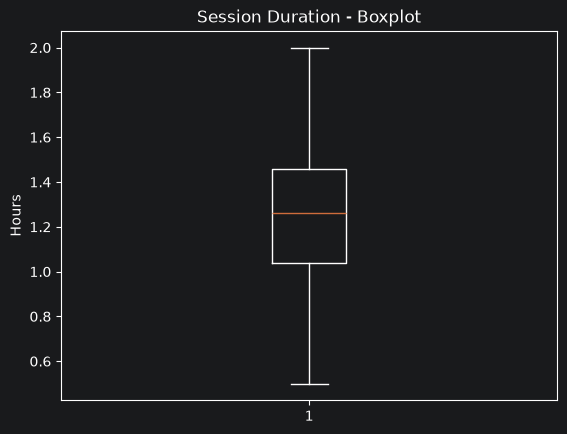

count    973.000000
mean       1.256423
std        0.343033
min        0.500000
25%        1.040000
50%        1.260000
75%        1.460000
max        2.000000
Name: Session_Duration (hours), dtype: float64

In [78]:
plt.boxplot(df['Session_Duration (hours)'])
plt.title('Session Duration - Boxplot')
plt.ylabel('Hours')
plt.show()

df['Session_Duration (hours)'].describe()

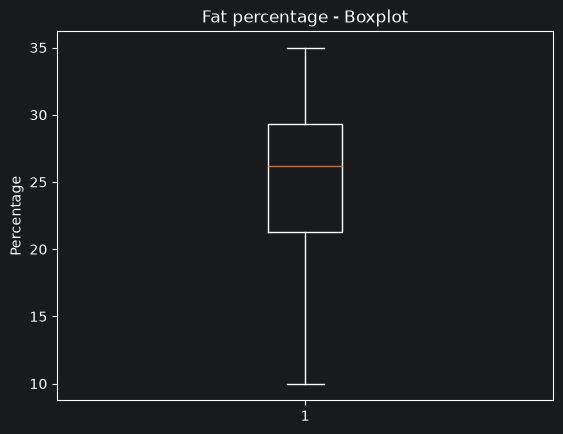

In [79]:
plt.boxplot(df['Fat_Percentage'])
plt.title("Fat percentage - Boxplot")
plt.ylabel('Percentage')
plt.show()

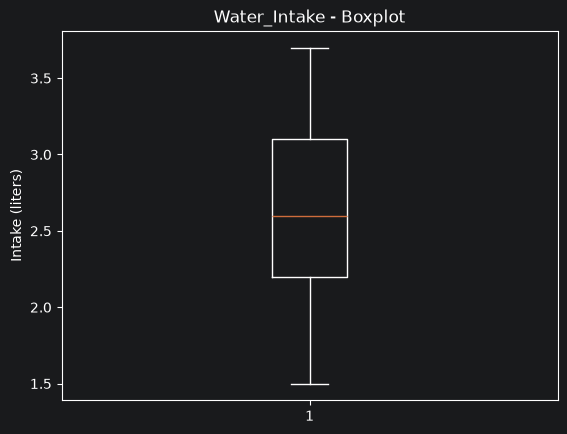

In [80]:
plt.boxplot(df['Water_Intake (liters)'])
plt.title("Water_Intake - Boxplot")
plt.ylabel('Intake (liters)')
plt.show()

In [81]:
print(df['Workout_Frequency (days/week)'].value_counts().sort_index())
print()
print(df['Experience_Level'].value_counts().sort_index())

Workout_Frequency (days/week)
2    197
3    368
4    306
5    102
Name: count, dtype: int64

Experience_Level
1    376
2    406
3    191
Name: count, dtype: int64


In [82]:
numeric_df = df.select_dtypes(include='number')

correlation_matrix = numeric_df.corr()

print(correlation_matrix)



                                    Age  Weight (kg)  Height (m)   Max_BPM  \
Age                            1.000000    -0.036699   -0.027837 -0.017073   
Weight (kg)                   -0.036699     1.000000    0.365507  0.057133   
Height (m)                    -0.027837     0.365507    1.000000 -0.017660   
Max_BPM                       -0.017073     0.057133   -0.017660  1.000000   
Avg_BPM                        0.035969     0.009628   -0.014776 -0.039751   
Resting_BPM                    0.004354    -0.032164   -0.005090  0.036647   
Session_Duration (hours)      -0.019912    -0.013313   -0.010206  0.010051   
Calories_Burned               -0.154679     0.095854    0.086348  0.002090   
Fat_Percentage                 0.002370    -0.225667   -0.235521 -0.009056   
Water_Intake (liters)          0.041528     0.394473    0.393533  0.031621   
Workout_Frequency (days/week)  0.008055    -0.011591   -0.011270 -0.029099   
Experience_Level              -0.018676     0.003668   -0.010267

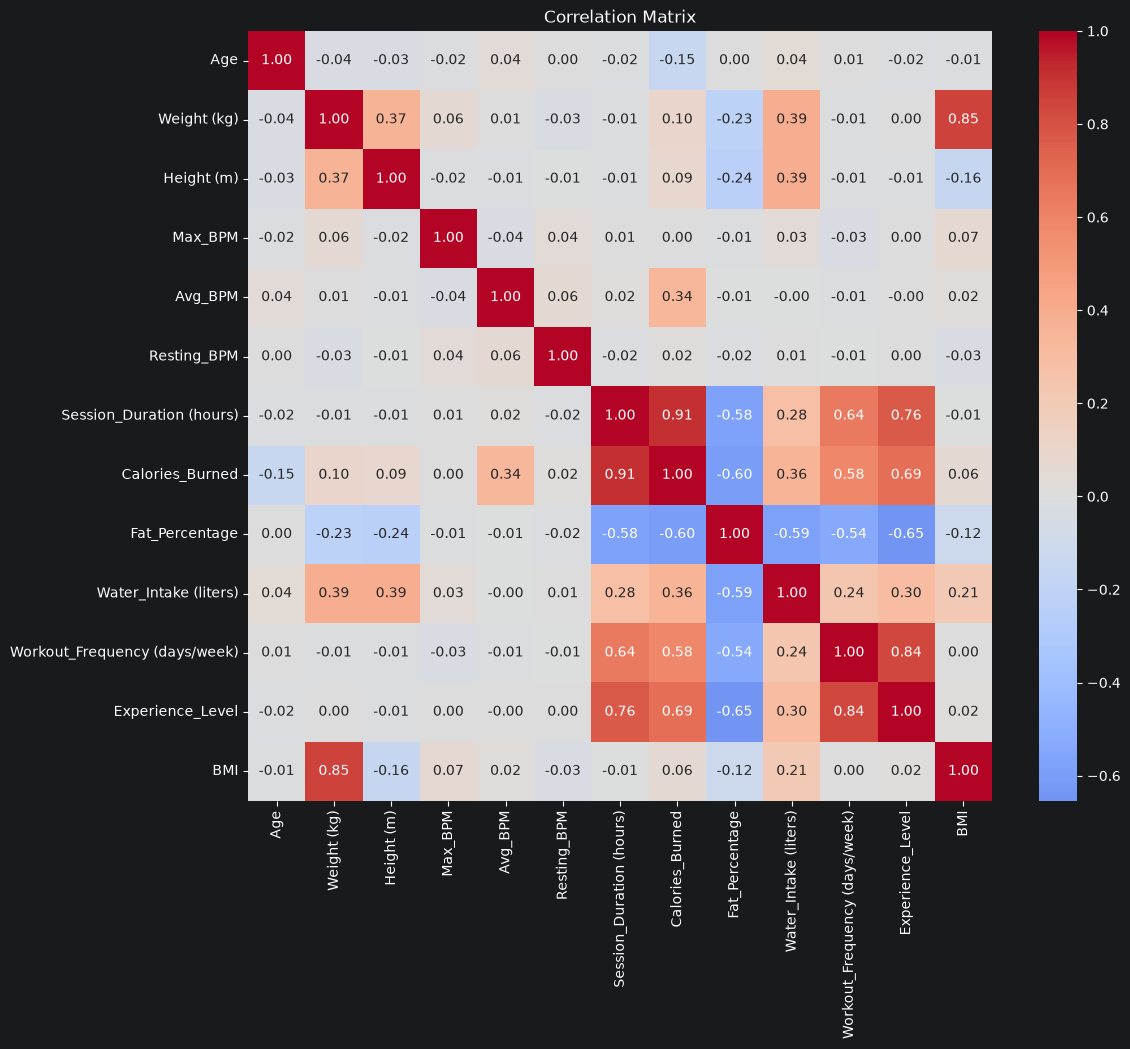

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))

sb.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Matrix')
plt.show()

In [84]:
#Izbacujemo expereince level, on ima visoku korelaciju sa dva atributa pa je najalkse njega izbaciti

In [85]:
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)'
]

X = df[features].copy()